# Imports

In [62]:
import os
import numpy as np
import pandas as pd
import transformers
import tensorflow as tf
import keras
import tqdm as tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import onnx
import onnxruntime as ort
from PIL import Image
from pathlib import Path
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import umap
from matplotlib.colors import BoundaryNorm

# Data

Load and prepare your dataset. Dataset should have at least 10k samples in it. Each dataset cannot be used by more than two students.

In [2]:
labels = [
    'Among Us', 
    'Apex Legends', 
    'Fortnite', 
    'Forza Horizon', 
    'Free Fire', 
    'Genshin Impact', 
    'God of War', 
    'Minecraft', 
    'Roblox', 
    'Terraria'
]

BASE_PATH = 'Dataset/'

In [3]:
X = []
y = []

for i, l in enumerate(labels):
    for p in Path(BASE_PATH + l).iterdir():
        X.append(str(p))
        y.append(i)

# X = np.array(X)
y = np.array(y, dtype='int32')
    

In [4]:
# class Dataset(keras.utils.PyDataset):
#     def __init__(self, X, y, batch_size, image_size=(3, 640, 360), seed=1, shuffle=True, **kwargs):
#         super().__init__(**kwargs)

#         self.X = X
#         self.y = y
#         self.batch_size = batch_size
#         self.image_size = image_size

#         self.shuffle = shuffle
#         self.rng = np.random.default_rng(seed)
#         self.indexes = np.arange(self.X.shape[0])

#     def __len__(self):
#         return -(-self.X.shape[0] // self.batch_size)

#     def __getitem__(self, idx):
#         ind = self.indexes[idx * self.batch_size, (idx + 1) * self.batch_size]
#         batch = keras.KerasTensor((self.batch_size, *self.image_size), dtype='float32')

#         for i, p in enumerate(self.X[ind]):
#             img = keras.utils.read_img(p)
#             batch[i] = keras.img_to_array(img) / 255

#         return batch, self.y[ind]

#     def on_epoch_end(self):
#         if self.shuffle:
#             self.rng.shuffle(self.indexes)

# Backbone

Load pretrained model from Hugging Face (or some other model repository if it's more convenient). Model should be trained on Feature Extraction task.

In [5]:
model_path = "dinov2_VITB_14.onnx"

options = ort.SessionOptions()

options.graph_optimization_level = (
    ort.GraphOptimizationLevel.ORT_ENABLE_ALL
)

options.intra_op_num_threads = 8
options.inter_op_num_threads = 1

session = ort.InferenceSession(
    model_path,
    sess_options=options,
    providers=["CPUExecutionProvider"]
)

In [6]:
for inp in session.get_inputs():
    print(inp.name, inp.shape, inp.type)

for out in session.get_outputs():
    print(out.name, out.shape, out.type)

pixel_values ['batch_size', 'num_channels', 'height', 'width'] tensor(float)
last_hidden_state ['batch_size', 'floor(height/14)*floor(width/14) + 1', 768] tensor(float)


In [7]:
processor = transformers.AutoImageProcessor.from_pretrained(
    "facebook/dinov2-base",
    size={"height": 350, "width": 630},
    crop_size={"height": 350, "width": 630}
)

def preprocess_image(img_path):
    img = []
    for p in img_path:
        img.append(Image.open(p).convert("RGB"))

    return processor(
        images=img,
        return_tensors="np"
    )

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


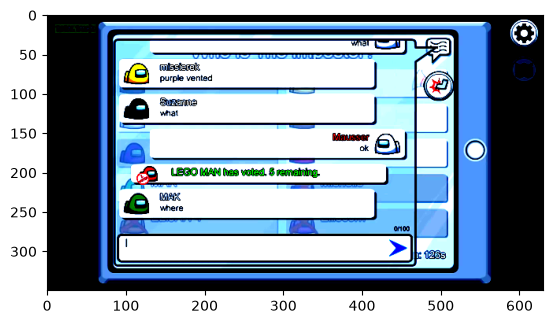

In [8]:
img = preprocess_image(X[5:10])['pixel_values']
plt.imshow(np.transpose(img[0], (1, 2, 0)))

# Feature extraction

Since we will not be training the backbone, extract features from your dataset.

Run the backbone on the images and save the extracted features. Don't forget to process the images. Images don't have to be of the same size, though it would be faster if they were. If the images don't fit in memory, lazily load them from disk

In [9]:
def get_embeddings(paths, session):
    imgs = preprocess_image(paths)

    return session.run(
        ['last_hidden_state'],
        imgs
    )[0][:, 0, :]

In [10]:
# emb = np.empty((len(X), 768))
# b_size = 10
# for i in tqdm.tqdm(range(0, len(X), b_size)):
#     emb[i:i + b_size] = get_embeddings(X[i:i + b_size], session)
# np.save('embeddings.npy', emb)

emb = np.load('embeddings.npy')

In [11]:
emb

array([[-0.15807675,  2.15404272,  0.3915723 , ..., -1.5852257 ,
        -0.41337985,  2.63641667],
       [ 2.18454409,  2.03919387,  0.50621355, ..., -1.56953514,
        -1.79067552,  2.16687679],
       [ 2.75298929,  0.47790197,  1.87134588, ..., -3.33713722,
        -2.25851512,  1.4740448 ],
       ...,
       [ 2.76713347,  1.29588664,  0.58637136, ..., -1.8924284 ,
        -1.23934829,  1.11333525],
       [ 3.0408628 ,  1.41763139,  0.44511542, ..., -1.86293685,
        -0.79883802,  1.16219115],
       [ 2.92451358,  1.49166214,  0.54638946, ..., -1.84003532,
        -0.71917307,  1.13316071]], shape=(10000, 768))

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


dist from 0 to 1:    0.712968220820724
dist from 0 to 2:    0.2217662881392127
dist from 1 to 2:    0.2540824910561519


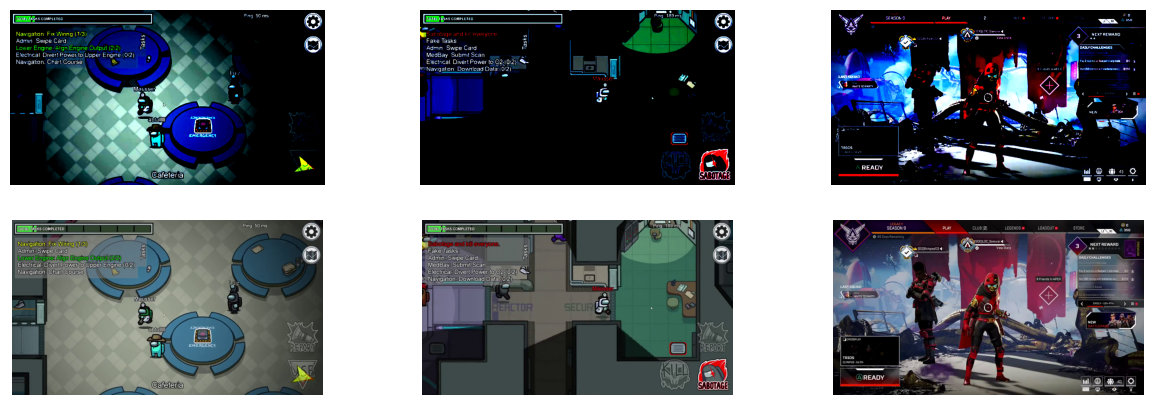

In [14]:
idxs = [100, 101, 1100]
imgs = preprocess_image([X[i] for i in idxs])['pixel_values']

fig, axes = plt.subplots(2, len(idxs), figsize=(15, 5))

for i in range(len(idxs)):
    axes[0, i].imshow(np.transpose(imgs[i], (1, 2, 0)))
    axes[0, i].axis('off')
    axes[1, i].imshow(Image.open(X[idxs[i]]).convert('RGB'))
    axes[1, i].axis('off')

for i, j in [(0, 1), (0, 2), (1, 2)]:
    e1 = emb[idxs[i]] / np.linalg.norm(emb[idxs[i]])
    e2 = emb[idxs[j]] / np.linalg.norm(emb[idxs[j]])

    print(f'dist from {i} to {j}:    {np.sum(e1 * e2)}')


# Prepare train/test data

Split your data (extracted features and labels) into train and test subsets.

In [15]:
indices = np.arange(len(emb))

X_train, X_val, y_train, y_val, idx_train, idx_val = train_test_split(
    emb, y, indices,
    test_size=0.1,
    shuffle=True,
    stratify=y,
)

Prepare `tf.data.Dataset` or some other way for the data to be used during training.

In [16]:
train_X = tf.data.Dataset.from_tensor_slices(X_train)
train_y = tf.data.Dataset.from_tensor_slices(y_train)
train_dataset = tf.data.Dataset.zip((train_X, train_y)).batch(128)

val_X = tf.data.Dataset.from_tensor_slices(X_val)
val_y = tf.data.Dataset.from_tensor_slices(y_val)
val_dataset = tf.data.Dataset.zip((val_X, val_y)).batch(128)

# Build the model

Build a simple model. The model should accept an extracted feature vector and return a vector of class logits (or probabilities). Model should only have a couple (or even 1) layers with weights.

In [30]:
def get_model(embed_size, n_classes, dense_size, dropout=0.2):
    inputs = x = keras.layers.Input((embed_size,))
    x = keras.layers.Dense(dense_size)(x)
    x = keras.activations.gelu(x)
    x = keras.layers.Dropout(dropout)(x)
    outputs = x = keras.layers.Dense(n_classes)(x)

    return keras.Model(inputs, outputs)


Compile the model. Choose loss and metrics.

In [34]:
EPOCHS = 10

STEPS_PER_EPOCH = len(train_dataset)
TOTAL_STEPS = STEPS_PER_EPOCH * EPOCHS
WARMUP_RATIO = 0.1
WARMUP_STEPS = int(TOTAL_STEPS * WARMUP_RATIO)

In [35]:
model = get_model(emb.shape[1], 10, 1024)

cosine_decay = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0,
    warmup_target=5e-4,
    warmup_steps=WARMUP_STEPS,
    decay_steps=TOTAL_STEPS - WARMUP_STEPS,
    alpha=0.1
)

model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=cosine_decay),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [36]:
def make_callbacks(name):
    return [
        keras.callbacks.ModelCheckpoint(
            filepath=f'{name}.keras',
            monitor='val_accuracy',
            mode='max',
            save_best_only=True,
            save_weights_only=False,
            verbose=1
        ),

        keras.callbacks.EarlyStopping(
            monitor='val_accuracy',
            patience=10,
            mode='max',
            restore_best_weights=True,
            verbose=1
        )
    ]

# Train the model

In [39]:
# model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=make_callbacks('model'))
model = keras.models.load_model('model.keras')

# Evaluation

Evalute the model on test data.

In [40]:
print(f'accuracy: {model.evaluate(val_dataset)[1]}')

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9930 - loss: 0.0244  
accuracy: 0.9929999709129333


Plot confusion matrix.

1/8 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/stepWARNING:tensorflow:5 out of the last 17 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7f08c68f05e0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


([<matplotlib.axis.YTick at 0x7f08c6780a50>,
 [Text(0, 0, 'Among Us'),
  Text(0, 1, 'Apex Legends'),
  Text(0, 2, 'Fortnite'),
  Text(0, 3, 'Forza Horizon'),
  Text(0, 4, 'Free Fire'),
  Text(0, 5, 'Genshin Impact'),
  Text(0, 6, 'God of War'),
  Text(0, 7, 'Minecraft'),
  Text(0, 8, 'Roblox'),
  Text(0, 9, 'Terraria')])

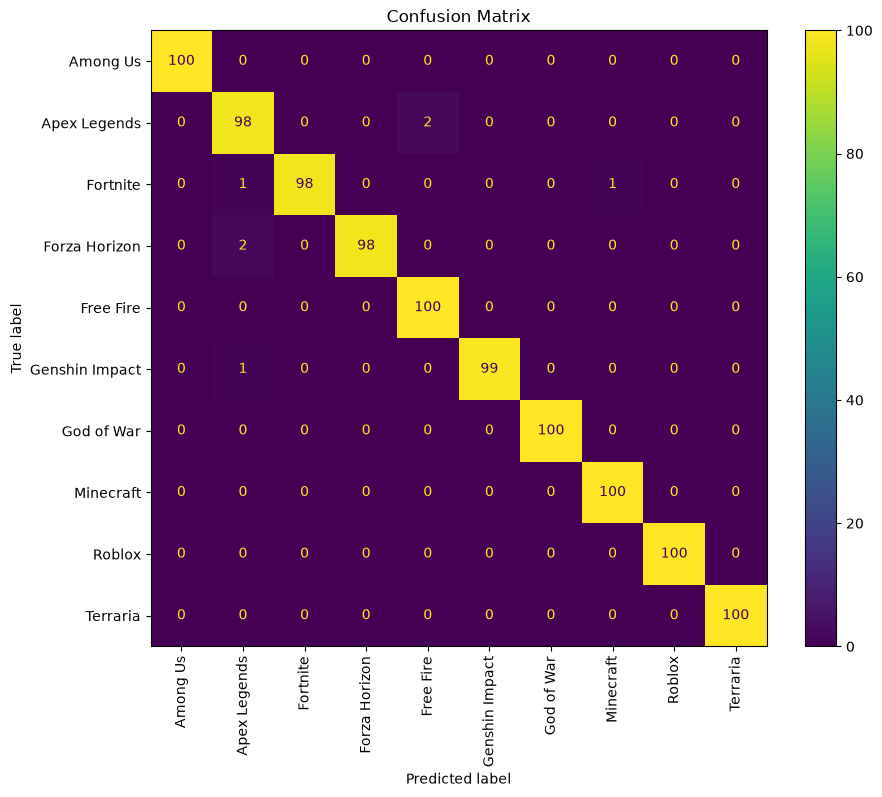

In [41]:
y_pred = np.argmax(model.predict(val_dataset), axis=-1)
conf_mat = confusion_matrix(y_val, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=conf_mat)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax)

plt.title("Confusion Matrix")
plt.xticks(range(len(labels)), labels, rotation=90)
plt.yticks(range(len(labels)), labels)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


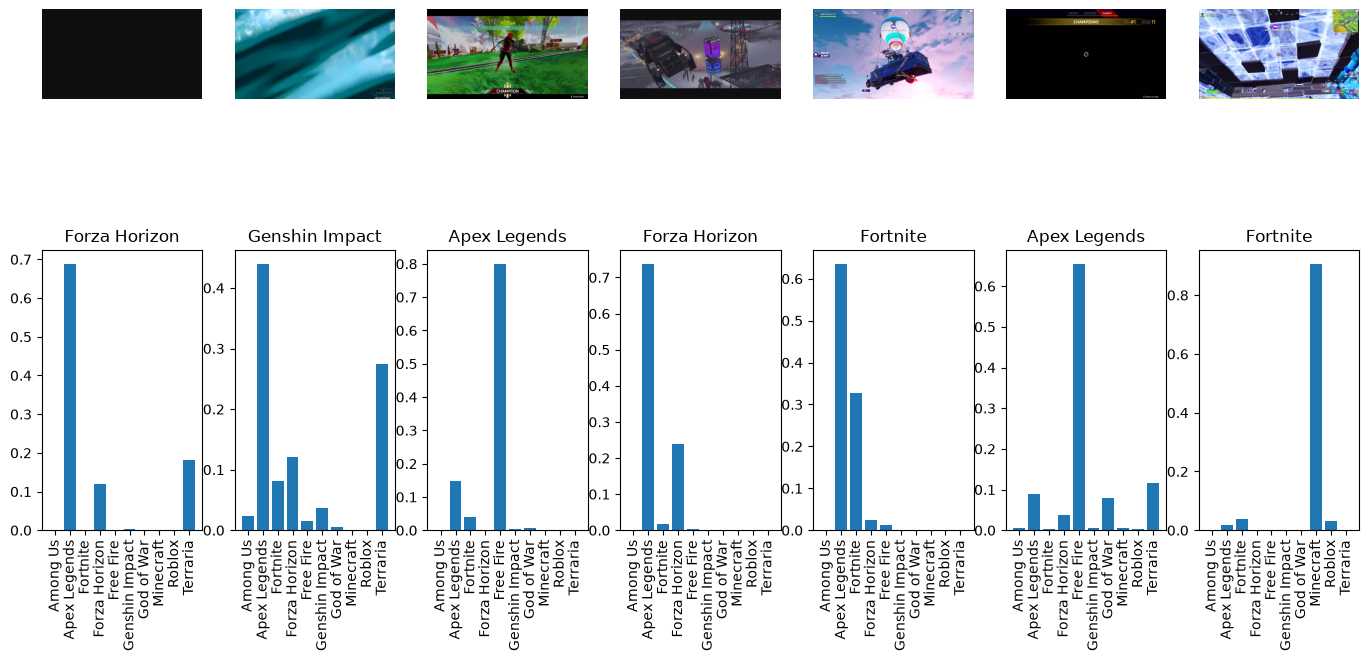

In [42]:
lim = 10
errors = np.where(y_val != y_pred)[0][:lim]
error_indices = idx_val[errors]

imgs = [Image.open(X[i]).convert('RGB') for i in error_indices]
imgs_pred = keras.ops.softmax(model.predict(X_val[errors]), axis=1)

fig, axes = plt.subplots(2, errors.shape[0], figsize=(17, 8))

for i in range(len(errors)):
    axes[0, i].imshow(imgs[i])
    axes[0, i].axis('off')
    axes[1, i].bar(range(10), imgs_pred[i])
    axes[1, i].set_xticks(range(10), labels, rotation=90)
    axes[1, i].set_title(labels[y_val[errors[i]]])


Perform dimensiality reduction and plot the extracted features. Do classes form clusters?

In [44]:
emb_mean = np.mean(emb, axis=0)
emb_var = np.var(emb, axis=0)

mean_emb_mean = np.mean(emb_mean)
var_emb_var = np.var(emb_var)
mean_emb_mean, var_emb_var

(np.float64(-0.006858039432552379), np.float64(0.27074406685075453))

In [107]:
emb_scaled = StandardScaler().fit_transform(emb)

reducer = umap.UMAP(
    n_neighbors=30,
    min_dist=0.2,
    n_components=2,
    compatibility_layout=False
)
emb_umap = reducer.fit_transform(emb_scaled)

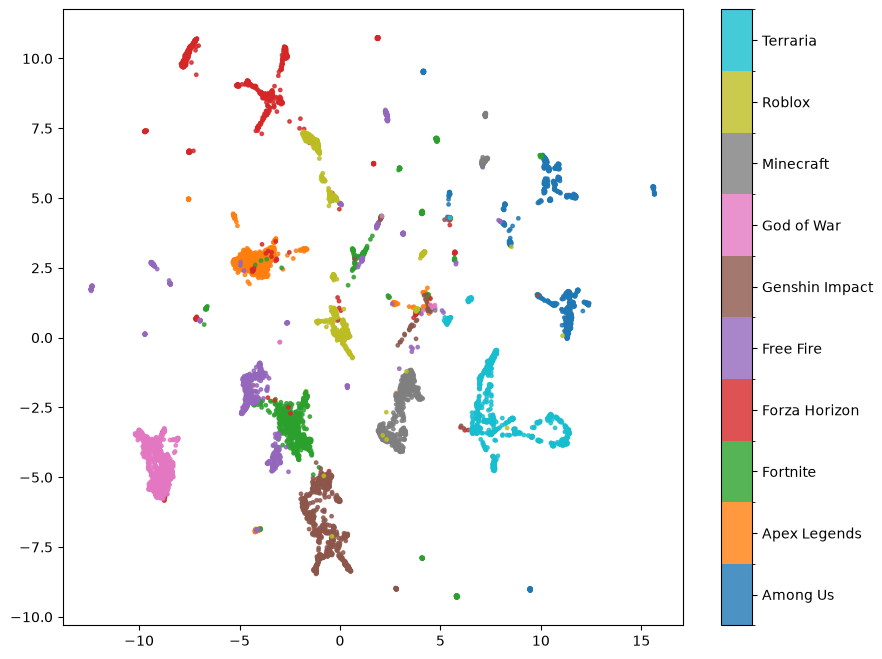

In [ ]:
plt.figure(figsize=(10, 8))

bounds = np.arange(-0.5, len(labels), 1.0)
cmap = plt.get_cmap('tab10', len(labels))
norm = BoundaryNorm(bounds, ncolors=cmap.N)

sc = plt.scatter(
    emb_umap[:, 0],
    emb_umap[:, 1],
    c=y,
    s=6,
    alpha=0.8,
    cmap=cmap,
    norm=norm,
)

cbar = plt.colorbar(sc, ticks=np.arange(len(labels)))
cbar.set_ticklabels(labels)

# Bonus

Check if the feature extractor model can be used without a classifier layer (how large is the average feature vector similarity inbetween same in different classes)

In [68]:
emb_normalized = emb / np.linalg.norm(emb, axis=1).reshape(-1, 1)

In [72]:
cos_by_classes = np.empty((len(labels), len(labels), 1000 * 1000))

for i in range(len(labels)):
    for j in range(len(labels)):
        cos_by_classes[i, j] = (emb_normalized[i * 1000:(i + 1) * 1000] @ emb_normalized[j * 1000:(j + 1) * 1000].T).ravel()


In [ ]:
cos_by_classes_avg = np.mean(cos_by_classes, axis=-1)
cos_by_classes_q10 = np.quantile(cos_by_classes, q=0.1, axis=-1)
cos_by_classes_q50 = np.quantile(cos_by_classes, q=0.5, axis=-1)
cos_by_classes_q90 = np.quantile(cos_by_classes, q=0.9, axis=-1)

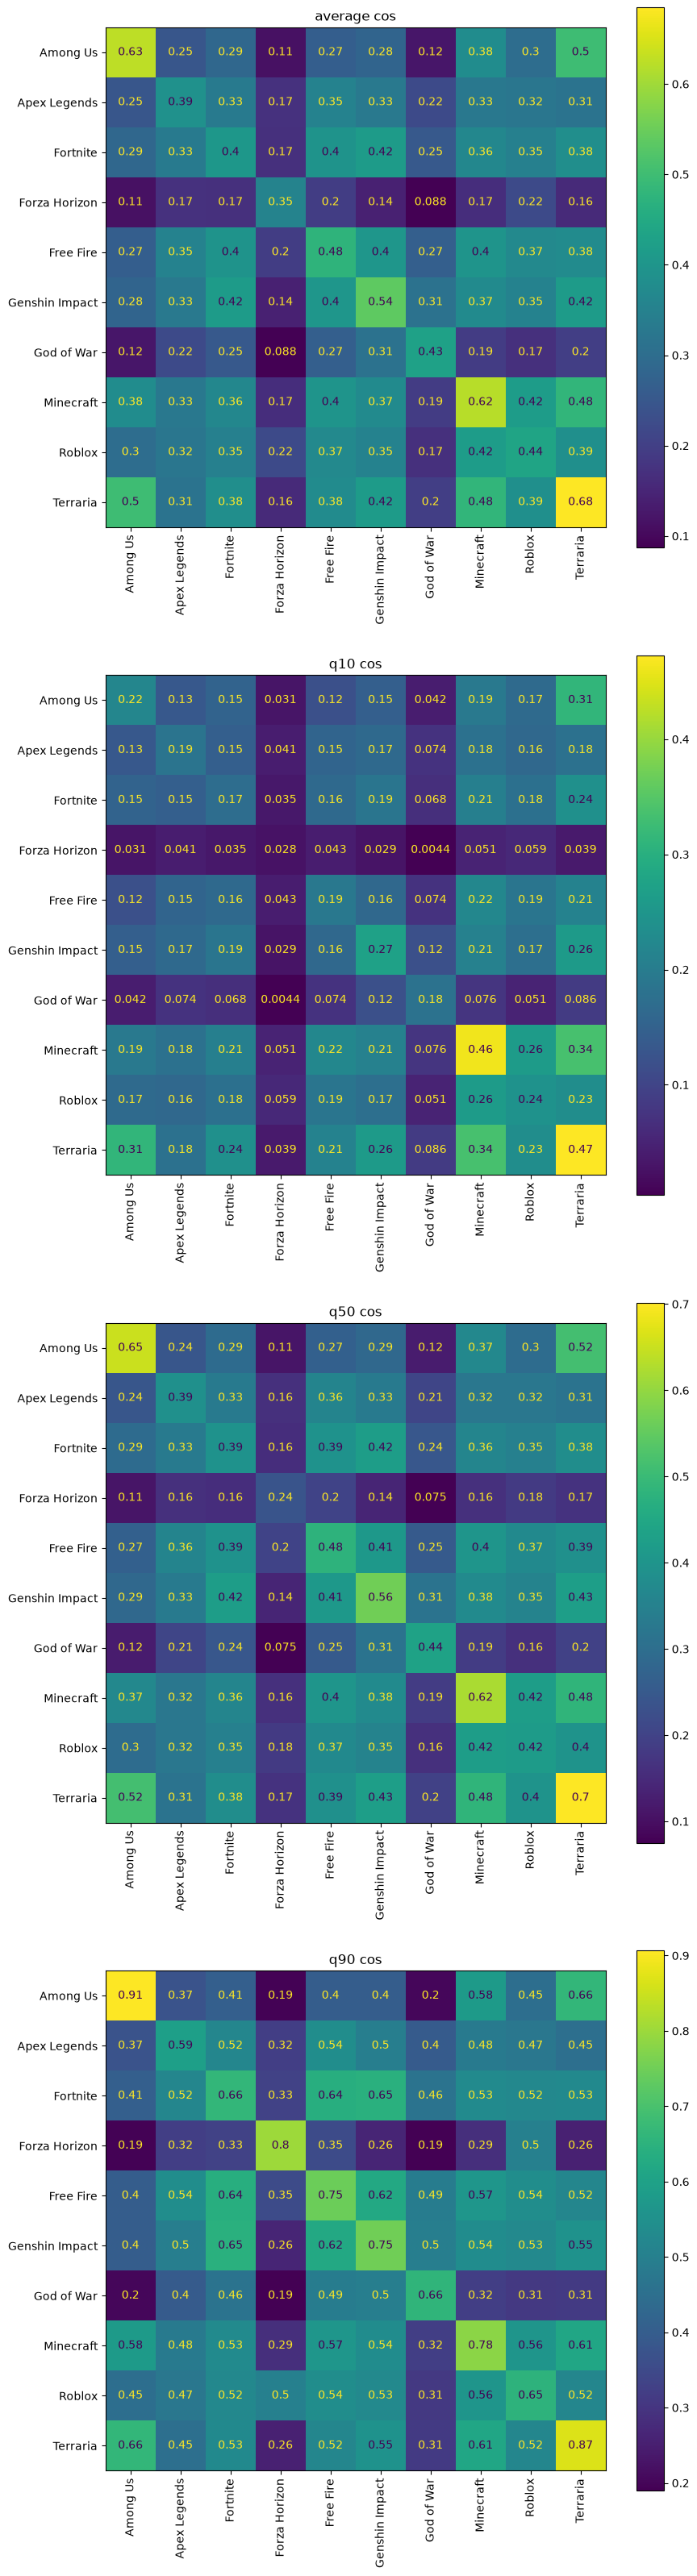

In [102]:
fig, axes = plt.subplots(4, 1, figsize=(10, 40))

for i, (mat, name) in enumerate(zip([cos_by_classes_avg, cos_by_classes_q10, cos_by_classes_q50, cos_by_classes_q90],
                     ['average', 'q10', 'q50', 'q90'])):

    disp = ConfusionMatrixDisplay(
        confusion_matrix=mat,
        display_labels=labels,
    )

    disp.plot(
        ax=axes[i],
        colorbar=True,
        xticks_rotation=90,
    )
    axes[i].set_title(name + ' cos')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')